# Module 7 Lab 2: Textbook Problem 7.1

### What Drives a Restaurant's Overall Rating?

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

Customers rated 15 restaurants on food, ambience, and service, plus an overall rating. This lab fits a linear regression to see which of the three moves the overall rating the most, so a struggling owner knows what to fix first.

## Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

ratings = pd.read_csv('ratings.tsv', sep='\t')   # tab-separated file
print(ratings.shape)
ratings

(15, 5)


,restaurant,food,ambience,service,rating
0,1,85,82,89,78
1,2,80,90,80,85
2,3,83,86,83,85
3,4,70,96,75,72
4,5,68,80,78,75
5,6,65,70,56,54
6,7,64,68,61,62
7,8,72,95,72,73
8,9,69,70,78,70
9,10,75,80,75,77


In [2]:
ratings[['food', 'ambience', 'service', 'rating']].describe().round(1)

,food,ambience,service,rating
count,15.0,15.0,15.0,15.0
mean,73.1,81.7,75.1,73.1
std,6.6,9.8,8.1,8.3
min,64.0,68.0,56.0,54.0
25%,68.5,71.0,73.5,70.5
50%,72.0,82.0,78.0,74.0
75%,77.5,90.0,78.0,77.5
max,85.0,96.0,89.0,85.0


## Part 1: The regression in math form

The outcome is the overall rating and the three predictors are the aspect ratings:

$$\text{rating} = \beta_0 + \beta_1 \cdot \text{ambience} + \beta_2 \cdot \text{food} + \beta_3 \cdot \text{service}$$

- $\beta_0$ is the constant (intercept)
- $\beta_1, \beta_2, \beta_3$ are how many points the overall rating moves when that aspect goes up 1 point, holding the other two the same

So there are 4 parameters to find. The "best" set is the one that makes the predictions miss the real ratings by the least, measured by the sum of squared errors (SSE).

## Part 2: Trying it by hand

Instead of solving it exactly, we tried a few guesses for the 4 parameters, worked out the predicted rating for Restaurant 1 (ambience 82, food 85, service 89, real rating 78), and then checked each guess's SSE across all 15 restaurants.

**Guess A: everything counts equally** ($\beta_0 = 0$, each slope $= 1/3$, just the average)

$$\hat{y} = 0 + \tfrac{1}{3}(82) + \tfrac{1}{3}(85) + \tfrac{1}{3}(89) = 85.33$$

**Guess B: only food matters** ($\beta_0 = 0$, $\beta_1 = 0$, $\beta_2 = 1$, $\beta_3 = 0$)

$$\hat{y} = 0 + 0(82) + 1(85) + 0(89) = 85$$

**Guess C: mostly food, a little service** ($\beta_0 = -10$, $\beta_1 = 0.1$, $\beta_2 = 0.8$, $\beta_3 = 0.25$)

$$\hat{y} = -10 + 0.1(82) + 0.8(85) + 0.25(89) = 88.45$$

In [3]:
def sse(b0, b_amb, b_food, b_serv):
    pred = b0 + b_amb * ratings['ambience'] + b_food * ratings['food'] + b_serv * ratings['service']
    return ((ratings['rating'] - pred) ** 2).sum()

guesses = pd.DataFrame({
    'guess': ['A: equal weights', 'B: food only', 'C: mostly food + service'],
    'b0':       [0,   0, -10],
    'ambience': [1/3, 0, 0.1],
    'food':     [1/3, 1, 0.8],
    'service':  [1/3, 0, 0.25],
})
guesses['SSE (all 15)'] = [sse(*row) for row in guesses[['b0', 'ambience', 'food', 'service']].values]
guesses.round(2)

,guess,b0,ambience,food,service,SSE (all 15)
0,A: equal weights,0,0.33,0.33,0.33,514.89
1,B: food only,0,0.00,1.00,0.00,289.00
2,C: mostly food + service,-10,0.10,0.80,0.25,290.46


Guess A misses the most. Leaning on food (B and C) cuts the error almost in half, which is already a hint about which aspect matters. Python can find the exact set that makes the SSE as small as possible.

## Part 3: Fit the regression in Python

In [4]:
X = ratings[['ambience', 'food', 'service']]
y = ratings['rating']

model = LinearRegression()
model.fit(X, y)

print(f'intercept: {model.intercept_:.2f}')
for name, c in zip(X.columns, model.coef_):
    print(f'{name:>9}: {c:.3f}')

print(f'\nR^2: {model.score(X, y):.3f}')
print(f'SSE of the fitted model: {((y - model.predict(X)) ** 2).sum():.1f}')

intercept: -15.87
 ambience: 0.134
     food: 0.734
  service: 0.324

R^2: 0.794
SSE of the fitted model: 199.3


We fit on all 15 restaurants because the goal here is reading the coefficients, and with only 15 rows a 70/30 split would leave just 10 to estimate 4 parameters. The fitted SSE (about 199) is lower than every one of our hand guesses, which is what "best fit" means.

**The fitted model:**

$$\widehat{\text{rating}} = -15.87 + 0.13 \cdot \text{ambience} + 0.73 \cdot \text{food} + 0.32 \cdot \text{service}$$

In plain terms: if a restaurant's food rating goes up 1 point (and ambience and service stay the same), its overall rating goes up about 0.73 points. One more point of service is worth about 0.32, and one more point of ambience only about 0.13. The model explains about 79% of the differences in overall rating ($R^2 \approx 0.79$).

## Ranking the factors

In [5]:
coef_table = (pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_})
              .sort_values('coefficient', ascending=False)
              .reset_index(drop=True))
coef_table.index = coef_table.index + 1   # rank 1, 2, 3
coef_table.round(3)

,feature,coefficient
1,food,0.734
2,service,0.324
3,ambience,0.134


All three aspects are rated on the same 0–100 scale, so the coefficients can be compared directly.

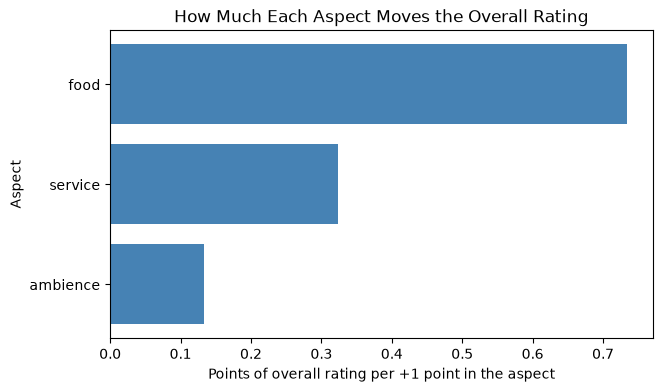

In [6]:
plt.figure(figsize=(7, 4))
plt.barh(coef_table['feature'][::-1], coef_table['coefficient'][::-1], color='steelblue')
plt.title('How Much Each Aspect Moves the Overall Rating')
plt.xlabel('Points of overall rating per +1 point in the aspect')
plt.ylabel('Aspect')
plt.show()

### Honest check: does the ranking hold on held-out data?

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
check = LinearRegression().fit(X_train, y_train)

print(pd.Series(check.coef_, index=X.columns).round(3))
print(f'R^2 on the 5 held-out restaurants: {check.score(X_test, y_test):.3f}')

ambience    0.074
food        0.957
service     0.204
dtype: float64
R^2 on the 5 held-out restaurants: 0.575


Trained on only 10 restaurants, the exact numbers move around (that's expected with so little data), but the order stays the same: food first, then service, then ambience.

## Recommendation

Food is the first thing to fix. Its coefficient is about 0.73, compared with 0.32 for service and 0.13 for ambience, so a one-point bump in food is linked to the biggest jump in the predicted overall rating. Since the model is based on only 15 restaurants, we'd treat this as a strong hint, not proof that fixing food alone will raise ratings.

## Appendix: AI Use

- **What Claude did:** helped with the regression syntax, the SSE function for the hand guesses, and the coefficient table and chart.
- **Key prompts (paraphrased):**
  - How do I fit a linear regression model with scikit-learn and interpret its coefficients?
  - How can I calculate the sum of squared errors for my hand-picked predictions and compare them?
  - How can I create a coefficient table and a chart to explain the regression results?
  - Refine my wording so it reads more professionally.